# GAF-CNN — Test Output (gaf_cnn.sh)

**Everything the test phase of `gaf_cnn.sh` produced: predictions, confusion matrix, accuracy, report**

<small>Notebook 2 of 3 &middot; generated automatically from the output files of the `gaf_cnn.sh` run, so it is reproducible: every number below is read from the files the run produced.</small>

## 0. Setup — imports and paths

The cell below finds the `GAF_CNN_Complete` folder automatically, so the notebook works wherever the folder is placed.

In [1]:
import json, os, re, sys, glob, hashlib
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, FileLink, Image as IPImage

%matplotlib inline


def find_bundle_root(start=None):
    """Walk up until we find the folder that contains run_output/gaf_cnn_sh."""
    p = Path(start or os.getcwd()).resolve()
    for cand in [p, *p.parents]:
        if (cand / "run_output" / "gaf_cnn_sh" / "training_console.txt").exists():
            return cand
        if (cand / "training_console.txt").exists():      # notebook inside run_output
            return cand.parent.parent
    raise FileNotFoundError("Could not find run_output/gaf_cnn_sh - run the notebook from inside "
                            "the GAF_CNN_Complete folder")


BUNDLE = find_bundle_root()
RUN    = BUNDLE / "run_output" / "gaf_cnn_sh"
CODE   = BUNDLE / "code"
NB_DIR = BUNDLE / "notebooks"
DATA   = BUNDLE / "data"
sys.path.insert(0, str(CODE))

# keep line length sane in the tables
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 50)

print("bundle folder :", BUNDLE)
print("run folder    :", RUN)
print("files in run  :", sorted(p.name for p in RUN.iterdir()))

bundle folder : /home/user/CHEM_GAF_CNN/GAF_CNN_Complete
run folder    : /home/user/CHEM_GAF_CNN/GAF_CNN_Complete/run_output/gaf_cnn_sh
files in run  : ['model', 'training_console.txt', 'training_console_clean.txt', 'training_curve_1_1.png', 'training_curve_1_2.png', 'training_epochs.csv', 'training_history.json']


## 1. The test output as the script printed it

After training, `gaf_cnn.py` loads the best saved model and runs it on the test split
(`shuffled/Test`, 25 images, no shuffling). Below is that part of the console output, verbatim.

In [2]:
raw = (RUN / "training_console.txt").read_text(errors="replace")
raw = re.sub(r"\x1b\[[0-9;]*[A-Za-z]", "", raw).replace("\b", "")

idx = raw.find("TESTING WITH -")
start = raw.rfind("*****", 0, idx)
start = raw.rfind("*****", 0, start) if start > 0 else idx
test_raw = raw[max(start, 0):].strip()

print(f"captured test output: {len(test_raw.splitlines())} lines")
print(test_raw)

captured test output: 88 lines
**********
                                TESTING WITH - CNN_5classes__epo_4000_pat_1000_batch_16_tl.keras
*********************************************************************************************
*********************************************************************************************
Found 25 images belonging to 5 classes.
Prediction of 25 rows.

 1/25 ━━━━━━━━━━━━━━━━━━━━ 2s 118ms/step
12/25 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step  
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step
[[9.04025495e-01 5.85781597e-03 2.24165898e-03 8.66819322e-02
  1.19311851e-03]
 [9.24723506e-01 6.92636054e-03 1.96530041e-03 6.52055964e-02
  1.17928616e-03]
 [9.35089648e-01 1.13996183e-02 2.23548152e-03 4.97878641e-02
  1.48735766e-03]
 [6.01190984e-01 2.68815190e-01 5.99411204e-02 6.46255463e-02
  5.42717520e-03]
 [9.34034646e-01 1.07770963e-02 4.48527513e-03 4.88198735e-02
  1.88318221e-03]
 [9.41867471e-01 3.86885442e-02 6.33440167e-03 1.08503755e-02
  2.25925120e-03]
 [9.8056

## 2. The same test, structured

The numbers above are the script's own output. To make them readable (and comparable with the report
files) the saved model is evaluated once more with the repository's evaluation helper
(`gaf_cnn_full_output.run_split`), which uses the same test set, the same generator settings
(`rescale 1/255`, `shuffle=False`, `batch_size=1`) and the same class order. The numbers are identical;
they are just written as tables instead of a printed array.

In [3]:
import importlib
import tensorflow as tf
import gaf_cnn_full_output as full_output
from gaf_cnn import simple_cnn
%matplotlib inline

# load the model this run produced (notebooks are independent of each other)
model_path = (sorted(RUN.glob("model/*.keras")) or sorted(CODE.glob("CNN_*classes_*.keras")))[0]
trained = simple_cnn(n_classes=5)
trained(tf.zeros((1, 224, 224, 3)))
trained.load_weights(model_path)
print("model evaluated :", model_path.name, f"({model_path.stat().st_size:,} bytes)")

TEST_DIR = DATA / "gafimages" / "shuffled" / "Test"
EVAL_DIR = RUN / "test_eval"
EVAL_DIR.mkdir(exist_ok=True)

import contextlib, io as _io
with contextlib.redirect_stdout(_io.StringIO()):
    summary = full_output.run_split(trained, str(TEST_DIR), "shuffled", str(EVAL_DIR), str(model_path))

print("test images      :", summary["n_test_images"], "in", len(summary["class_names"]), "classes")
print("correct / wrong  :", summary["n_correct"], "/", summary["n_wrong"])
print("accuracy         :", f"{summary['accuracy_percent']:.2f} %")
print("result files     :", sorted(p.name for p in EVAL_DIR.iterdir()))

/home/user/.venv/lib/python3.11/site-packages/keras/src/layers/convolutional/base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


/home/user/.venv/lib/python3.11/site-packages/keras/src/saving/saving_lib.py:415: UserWarning: Skipping variable loading for optimizer 'SGD', because it has 2 variables whereas the saved optimizer has 22 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))
/home/user/.venv/lib/python3.11/site-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


model evaluated : CNN_5classes__epo_4000_pat_1000_batch_16_tl.keras (230,098 bytes)


test images      : 25 in 5 classes
correct / wrong  : 23 / 2
accuracy         : 92.00 %
result files     : ['shuffled_classification_report.txt', 'shuffled_confusion_matrix.csv', 'shuffled_confusion_matrix.png', 'shuffled_full_output.txt', 'shuffled_predictions.csv', 'shuffled_summary.json']


## 3. Overall result and accuracy per class

In [4]:
display(Markdown(f"### Accuracy: **{summary['accuracy_percent']:.2f} %** "
                 f"({summary['n_correct']} of {summary['n_test_images']} test images correct)"))

per_class = pd.DataFrame({
    "class": summary["class_names"],
    "accuracy %": [summary["accuracy_by_class_percent"][c] for c in summary["class_names"]],
}).set_index("class")
display(per_class.round(2))

display(Markdown("### Confusion matrix (rows = true class, columns = predicted class)"))
cm = pd.DataFrame(summary["confusion_matrix"], index=summary["class_names"], columns=summary["class_names"])
display(cm)

### Accuracy: **92.00 %** (23 of 25 test images correct)

,accuracy %
class,
Benzochinone,100.0
Catecolo,100.0
Ferro-Ferri,60.0
Idrochinone,100.0
Idrochinone-Benzochinone,100.0


### Confusion matrix (rows = true class, columns = predicted class)

,Benzochinone,Catecolo,Ferro-Ferri,Idrochinone,Idrochinone-Benzochinone
Benzochinone,9,0,0,0,0
Catecolo,0,4,0,0,0
Ferro-Ferri,0,0,3,1,1
Idrochinone,0,0,0,4,0
Idrochinone-Benzochinone,0,0,0,0,3


## 4. Confusion matrix - figure

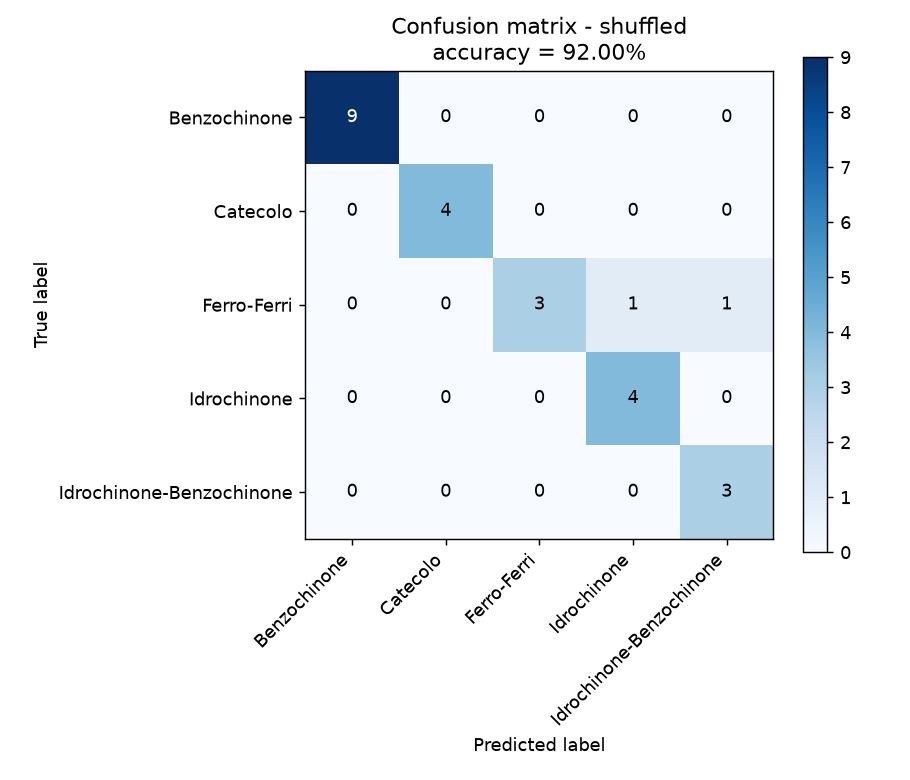

figure saved as: run_output/gaf_cnn_sh/test_eval/shuffled_confusion_matrix.png


In [5]:
from IPython.display import Image as _Img
png = EVAL_DIR / 'shuffled_confusion_matrix.png'
if png.exists():
    display(_Img(filename=str(png), width=520))
    print('figure saved as:', png.relative_to(BUNDLE).as_posix())


## 5. Classification report (precision / recall / F1)

In [6]:
print((EVAL_DIR / "shuffled_classification_report.txt").read_text())

CNN classification report - split: shuffled
model: CNN_5classes__epo_4000_pat_1000_batch_16_tl.keras
                          precision    recall  f1-score   support

            Benzochinone     1.0000    1.0000    1.0000         9
                Catecolo     1.0000    1.0000    1.0000         4
             Ferro-Ferri     1.0000    0.6000    0.7500         5
             Idrochinone     0.8000    1.0000    0.8889         4
Idrochinone-Benzochinone     0.7500    1.0000    0.8571         3

                accuracy                         0.9200        25
               macro avg     0.9100    0.9200    0.8992        25
            weighted avg     0.9380    0.9200    0.9151        25



## 6. Per image predictions

Every test image, the class the model predicted and the confidence (probability of the winning class). Wrong predictions are shown in red.

In [7]:
pred = pd.read_csv(EVAL_DIR / "shuffled_predictions.csv")
show = pd.DataFrame({
    "#": range(len(pred)),
    "file": pred["file"],
    "true class": pred["true_class"],
    "predicted class": pred["predicted_class"],
    "confidence": pred["max_confidence"].round(4),
    "result": pred["correct"].astype(str).map({"True": "OK", "False": "WRONG"}),
})

try:
    display(show.style.apply(lambda r: ["background-color: #ffe3e3" if r["result"] == "WRONG" else "" for _ in r], axis=1))
except Exception:
    display(show)

,#,file,true class,predicted class,confidence,result
0,0,0.01mMSPE-Benzochinone_2.png,Benzochinone,Benzochinone,0.904000,OK
1,1,0.01mMSPE-Benzochinone_3.png,Benzochinone,Benzochinone,0.924700,OK
2,2,0.1mMSPE-Benzochinone_2.png,Benzochinone,Benzochinone,0.935100,OK
3,3,0.5mMSPE-Benzochinone_2.png,Benzochinone,Benzochinone,0.601200,OK
4,4,1mMSPE-Benzochinone_1.png,Benzochinone,Benzochinone,0.934000,OK
5,5,1mMSPE-Benzochinone_3.png,Benzochinone,Benzochinone,0.941900,OK
6,6,2mMSPE-Benzochinone_1.png,Benzochinone,Benzochinone,0.980600,OK
7,7,2mMSPE-Benzochinone_2.png,Benzochinone,Benzochinone,0.981200,OK
8,8,2mMSPE-Benzochinone_3.png,Benzochinone,Benzochinone,0.980000,OK
9,9,0.01mMSPE-Catecolo_1.png,Catecolo,Catecolo,0.752800,OK


## 7. Misclassified images

### 2 misclassified image(s) out of 25

**2mMSPE-Ferro-Ferri_1.png** — true `Ferro-Ferri`, predicted `Idrochinone` (confidence 0.4079)

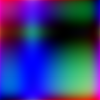

,probability
Benzochinone,0.0815
Catecolo,0.0666
Ferro-Ferri,0.3776
Idrochinone,0.4079
Idrochinone-Benzochinone,0.0664


**2mMSPE-Ferro-Ferri_3.png** — true `Ferro-Ferri`, predicted `Idrochinone-Benzochinone` (confidence 0.4881)

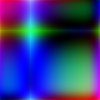

,probability
Benzochinone,0.1121
Catecolo,0.1073
Ferro-Ferri,0.0272
Idrochinone,0.2653
Idrochinone-Benzochinone,0.4881


In [8]:
wrong = pred[pred["correct"].astype(str) == "False"]
if len(wrong) == 0:
    display(Markdown("### No misclassified images — every test image was classified correctly."))
else:
    display(Markdown(f"### {len(wrong)} misclassified image(s) out of {len(pred)}"))
    for _, r in wrong.iterrows():
        display(Markdown(f"**{r['file']}** — true `{r['true_class']}`, predicted "
                         f"`{r['predicted_class']}` (confidence {r['max_confidence']:.4f})"))
        hits = glob.glob(str(DATA / "gafimages" / "shuffled" / "Test" / r["true_class"] / r["file"]))
        if hits:
            display(IPImage(filename=hits[0], width=190))
        probs = pd.DataFrame({c: [round(float(r[f"prob_{c}"]), 4)] for c in summary["class_names"]},
                             index=["probability"]).T
        display(probs)

## 8. Full probability matrix and downloads

In [9]:
display(Markdown("### Probability of each class for every test image"))
probs = pred[["file", "true_class"] + [f"prob_{c}" for c in summary["class_names"]]].copy()
probs.columns = ["file", "true"] + summary["class_names"]
display(probs.round(4))

### Probability of each class for every test image

,file,true,Benzochinone,Catecolo,Ferro-Ferri,Idrochinone,Idrochinone-Benzochinone
0,0.01mMSPE-Benzochinone_2.png,Benzochinone,0.9040,0.0059,0.0022,0.0867,0.0012
1,0.01mMSPE-Benzochinone_3.png,Benzochinone,0.9247,0.0069,0.0020,0.0652,0.0012
2,0.1mMSPE-Benzochinone_2.png,Benzochinone,0.9351,0.0114,0.0022,0.0498,0.0015
3,0.5mMSPE-Benzochinone_2.png,Benzochinone,0.6012,0.2688,0.0599,0.0646,0.0054
4,1mMSPE-Benzochinone_1.png,Benzochinone,0.9340,0.0108,0.0045,0.0488,0.0019
5,1mMSPE-Benzochinone_3.png,Benzochinone,0.9419,0.0387,0.0063,0.0109,0.0023
6,2mMSPE-Benzochinone_1.png,Benzochinone,0.9806,0.0012,0.0059,0.0112,0.0011
7,2mMSPE-Benzochinone_2.png,Benzochinone,0.9812,0.0021,0.0123,0.0028,0.0015
8,2mMSPE-Benzochinone_3.png,Benzochinone,0.9800,0.0017,0.0125,0.0042,0.0017
9,0.01mMSPE-Catecolo_1.png,Catecolo,0.1987,0.7528,0.0201,0.0253,0.0031


In [10]:
display(Markdown("### Download"))
for label, p in [
    ("Per image predictions (CSV)", EVAL_DIR / "shuffled_predictions.csv"),
    ("Confusion matrix (CSV)", EVAL_DIR / "shuffled_confusion_matrix.csv"),
    ("Confusion matrix (PNG)", EVAL_DIR / "shuffled_confusion_matrix.png"),
    ("Classification report", EVAL_DIR / "shuffled_classification_report.txt"),
    ("Summary (JSON)", EVAL_DIR / "shuffled_summary.json"),
    ("Full text output", EVAL_DIR / "shuffled_full_output.txt"),
    ("Raw console output of the run", RUN / "training_console.txt"),
]:
    if Path(p).exists():
        display(FileLink(str(p), result_html_prefix=f"{label}: "))
    else:
        print(f"{label}: not found ({p})")

### Download

/home/user/CHEM_GAF_CNN/GAF_CNN_Complete/run_output/gaf_cnn_sh/test_eval/shuffled_predictions.csv

/home/user/CHEM_GAF_CNN/GAF_CNN_Complete/run_output/gaf_cnn_sh/test_eval/shuffled_confusion_matrix.csv

/home/user/CHEM_GAF_CNN/GAF_CNN_Complete/run_output/gaf_cnn_sh/test_eval/shuffled_confusion_matrix.png

/home/user/CHEM_GAF_CNN/GAF_CNN_Complete/run_output/gaf_cnn_sh/test_eval/shuffled_classification_report.txt

/home/user/CHEM_GAF_CNN/GAF_CNN_Complete/run_output/gaf_cnn_sh/test_eval/shuffled_summary.json

/home/user/CHEM_GAF_CNN/GAF_CNN_Complete/run_output/gaf_cnn_sh/test_eval/shuffled_full_output.txt

/home/user/CHEM_GAF_CNN/GAF_CNN_Complete/run_output/gaf_cnn_sh/training_console.txt